## 1. Setup and load data

In [ ]:
import pandas as pd
numpy as np, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_auc_score, roc_curve, recall_score, precision_score,
                             accuracy_score, confusion_matrix, classification_report)
os.makedirs('images', exist_ok=True)

df = pd.read_csv('waze_dataset.csv')
print('rows:', len(df), '| columns:', df.shape[1])
df.head()

rows: 14999 | columns: 13


,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
0,0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android
1,1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone
2,2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android
3,3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone
4,4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android


In [ ]:
df.isna().sum()

ID                           0
label                      700
sessions                     0
drives                       0
total_sessions               0
n_days_after_onboarding      0
total_navigations_fav1       0
total_navigations_fav2       0
driven_km_drives             0
duration_minutes_drives      0
activity_days                0
driving_days                 0
device                       0
dtype: int64

In [ ]:
# The 700 unlabeled users can't be used for training, so drop them. ID is just an identifier.
df = df.dropna(subset=['label']).drop(columns='ID').copy()
df['churn'] = (df.label == 'churned').astype(int)
print('labeled users:', len(df), '| churn rate:', round(df.churn.mean() * 100, 2), '%'
)

labeled users: 14299 | churn rate: 17.74 %


## 2. Explore

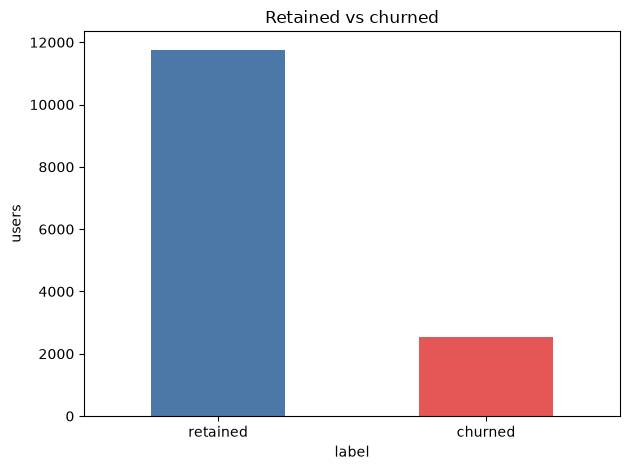

In [ ]:
ax = df.label.value_counts().plot(kind='bar', color=['#4c78a8', '#e45756'], rot=0)
ax.set_title('Retained vs churned'); ax.set_ylabel('users')
plt.tight_layout(); plt.savefig('images/waze_target_distribution.png', dpi=130); plt.show()

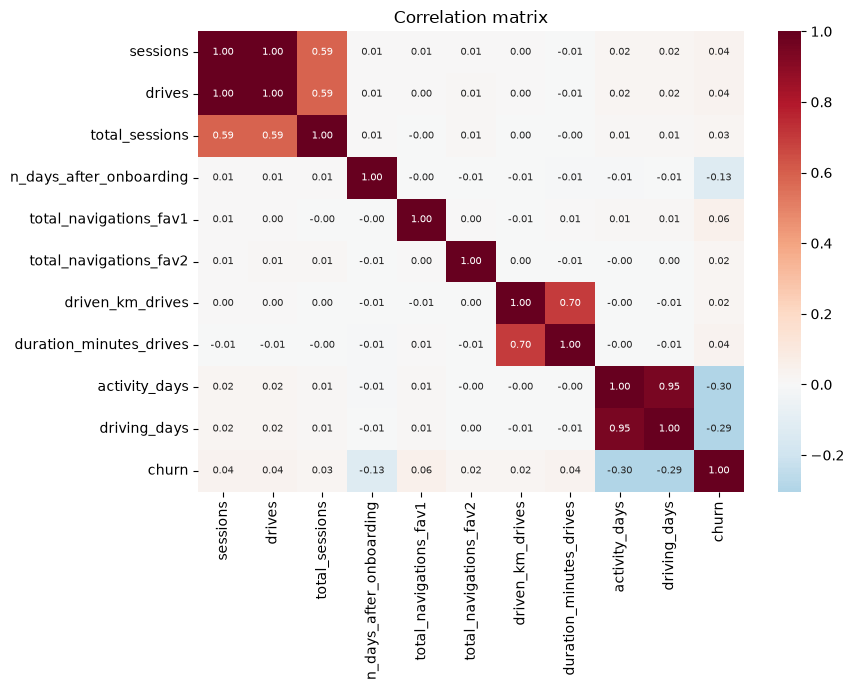

activity_days             -0.303851
driving_days              -0.294259
n_days_after_onboarding   -0.129263
driven_km_drives           0.019050
total_navigations_fav2     0.020051
total_sessions             0.025046
duration_minutes_drives    0.035678
sessions                   0.038045
drives                     0.038548
total_navigations_fav1     0.055537
churn                      1.000000
Name: churn, dtype: float64

In [ ]:
num = df.select_dtypes('number')
plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(), cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation matrix'); plt.tight_layout()
plt.savefig('images/waze_correlation_heatmap.png', dpi=130); plt.show()
num.corr()['churn'].sort_values()

## 3. Feature engineering and train/test split


In [ ]:
df['device_iphone'] = (df.device == 'iPhone').astype(int)
df['no_driving_days'] = (df.driving_days == 0).astype(int)
dd = df.driving_days.replace(0, np.nan)
df['km_per_driving_day'] = (df.driven_km_drives / dd).fillna(0)
df['km_per_drive'] = (df.driven_km_drives / df.drives.replace(0, np.nan)).fillna(0)
df['pct_sessions_in_month'] = df.sessions / df.total_sessions
df['drives_per_driving_day'] = (df.drives / dd).fillna(0)
df['fav_navs'] = df.total_navigations_fav1 + df.total_navigations_fav2
df['pro_driver'] = ((df.drives >= 60) & (df.driving_days >= 15)).astype(int)

features = [c for c in df.columns if c not in ('label', 'churn', 'device')]
X, y = df[features], df.churn

# 80/20 split; stratify keeps the same churn rate in both parts
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('train:', Xtr.shape, '| test:', Xte.shape)

train: (11439, 18) | test: (2860, 18)


In [ ]:
# Helper used by both models: prints the scores and returns them for the comparison table
def evaluate(name, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    scores = {'Model': name,
              'Accuracy': accuracy_score(yte, pred),
              'Churn recall': recall_score(yte, pred),
              'Churn precision': precision_score(yte, pred),
              'ROC-AUC': roc_auc_score(yte, proba)}
    print(name)
    for k, v in scores.items():
        if k != 'Model': print(f'  {k:16s}{v:.3f}')
    print()
    print(classification_report(yte, pred, target_names=['retained', 'churned']))
    return pred, scores

## 4. Model A: Logistic Regression

In [ ]:
logreg = make_pipeline(StandardScaler(),
                       LogisticRegression(class_weight='balanced', max_iter=1000))
logreg.fit(Xtr, ytr)
lr_proba = logreg.predict_proba(Xte)[:, 1]
lr_pred, lr_scores = evaluate('Logistic Regression', lr_proba)

Logistic Regression
  Accuracy        0.671
  Churn recall    0.704
  Churn precision 0.311
  ROC-AUC         0.744

              precision    recall  f1-score   support

    retained       0.91      0.66      0.77      2353
     churned       0.31      0.70      0.43       507

    accuracy                           0.67      2860
   macro avg       0.61      0.68      0.60      2860
weighted avg       0.81      0.67      0.71      2860



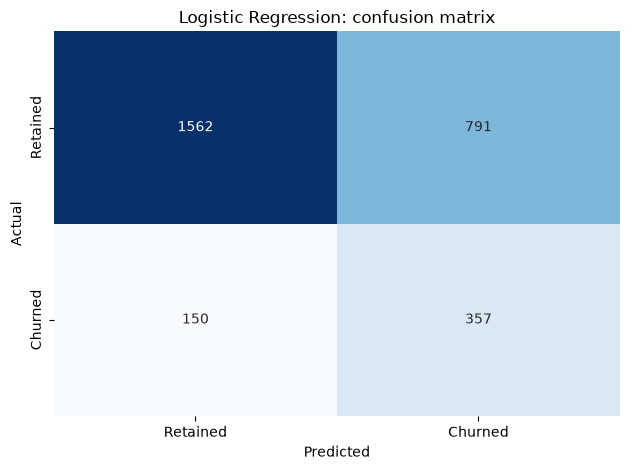

In [ ]:
cm = confusion_matrix(yte, lr_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
plt.title('Logistic Regression: confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.savefig('images/logreg_confusion_matrix.png', dpi=130); plt.show()

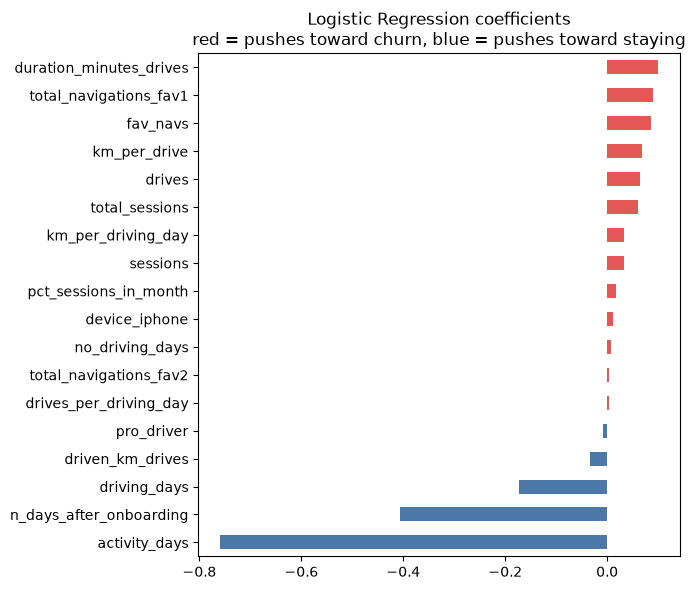

activity_days             -0.759195
n_days_after_onboarding   -0.405678
driving_days              -0.172131
duration_minutes_drives    0.099926
total_navigations_fav1     0.089333
fav_navs                   0.086429
dtype: float64

In [ ]:
coef = pd.Series(logreg[-1].coef_[0], features).sort_values()
coef.plot(kind='barh', color=['#e45756' if v > 0 else '#4c78a8' for v in coef], figsize=(7, 6))
plt.title('Logistic Regression coefficients\nred = pushes toward churn, blue = pushes toward staying')
plt.tight_layout(); plt.savefig('images/logreg_coefficients.png', dpi=130); plt.show()
coef.sort_values(key=abs, ascending=False).head(6)

In [ ]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (lr_proba >= t).astype(int)
    rows.append([t, recall_score(yte, p), precision_score(yte, p), int(p.sum())])
pd.DataFrame(rows, columns=['threshold', 'recall', 'precision', 'users_flagged']).round(3)

,threshold,recall,precision,users_flagged
0,0.3,0.899,0.244,1867
1,0.4,0.821,0.280,1487
2,0.5,0.704,0.311,1148
3,0.6,0.540,0.350,783
4,0.7,0.373,0.409,462


## 5. Model B: Random Forest

In [ ]:
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=20,
                            class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(Xtr, ytr)
rf_proba = rf.predict_proba(Xte)[:, 1]
rf_pred, rf_scores = evaluate('Random Forest', rf_proba)

Random Forest
  Accuracy        0.691
  Churn recall    0.663
  Churn precision 0.320
  ROC-AUC         0.740

              precision    recall  f1-score   support

    retained       0.91      0.70      0.79      2353
     churned       0.32      0.66      0.43       507

    accuracy                           0.69      2860
   macro avg       0.61      0.68      0.61      2860
weighted avg       0.80      0.69      0.72      2860



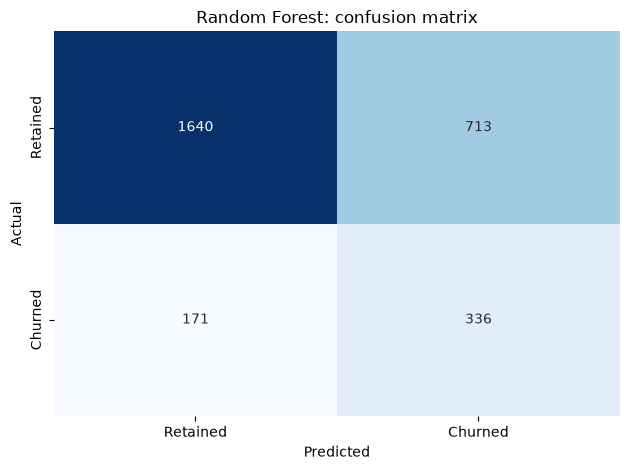

In [ ]:
cm = confusion_matrix(yte, rf_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
plt.title('Random Forest: confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.savefig('images/rf_confusion_matrix.png', dpi=130); plt.show()

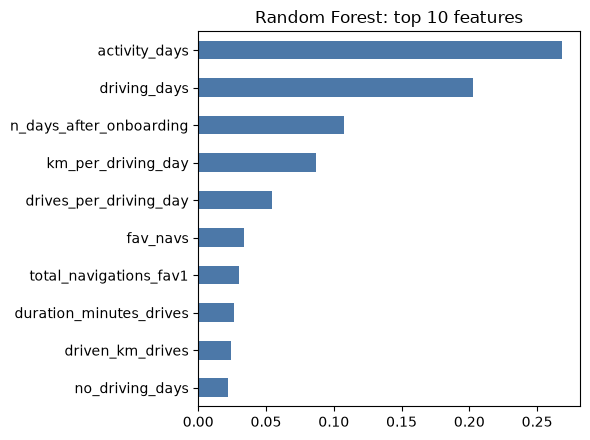

activity_days              0.268213
driving_days               0.202546
n_days_after_onboarding    0.107261
km_per_driving_day         0.086853
drives_per_driving_day     0.054228
fav_navs                   0.033495
dtype: float64

In [ ]:
imp = pd.Series(rf.feature_importances_, features).sort_values()
imp.tail(10).plot(kind='barh', color='#4c78a8', figsize=(6, 4.5))
plt.title('Random Forest: top 10 features')
plt.tight_layout(); plt.savefig('images/rf_feature_importance.png', dpi=130); plt.show()
imp.sort_values(ascending=False).head(6)

In [ ]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (rf_proba >= t).astype(int)
    rows.append([t, recall_score(yte, p), precision_score(yte, p), int(p.sum())])
pd.DataFrame(rows, columns=['threshold', 'recall', 'precision', 'users_flagged']).round(3)

,threshold,recall,precision,users_flagged
0,0.3,0.874,0.245,1808
1,0.4,0.791,0.283,1416
2,0.5,0.663,0.320,1049
3,0.6,0.497,0.346,729
4,0.7,0.310,0.439,358


## 6. Compare the two models

In [ ]:
results = pd.DataFrame([lr_scores, rf_scores]).round(3)
results

,Model,Accuracy,Churn recall,Churn precision,ROC-AUC
0,Logistic Regression,0.671,0.704,0.311,0.744
1,Random Forest,0.691,0.663,0.320,0.740


In [1]:
plt.figure(figsize=(5.5, 5))
for name, p in [('Logistic Regression', lr_proba), ('Random Forest', rf_proba)]:
    f, t, _ = roc_curve(yte, p)
    plt.plot(f, t, label=f'{name} ({roc_auc_score(yte, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend()
plt.title('ROC curves'); plt.tight_layout(); plt.savefig('images/waze_roc_curves.png', dpi=130); plt.show()

NameError: name 'plt' is not defined